<a href="https://colab.research.google.com/github/DanyRE4020/Concentracion_IA_avanzada/blob/main/Notebook9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore", category=FutureWarning) # keep library deprecation notices out of class
plt.rcParams["figure.figsize"] = (11, 3.4)

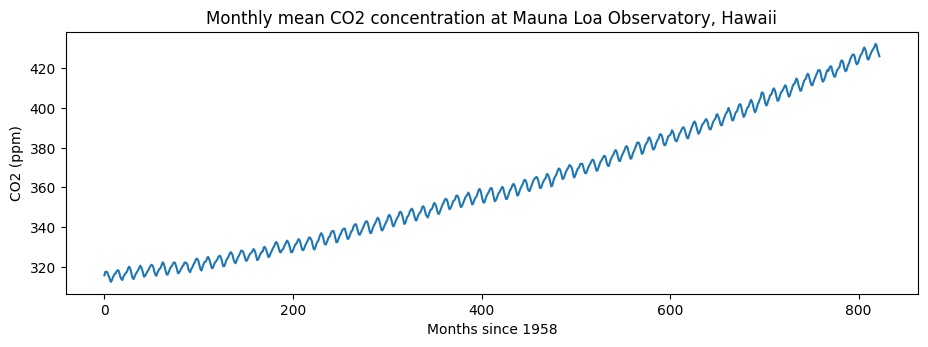

In [2]:
URL= "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
raw= pd.read_csv(URL, comment="#")
co2=raw['average']
co2.plot(title='Monthly mean CO2 concentration at Mauna Loa Observatory, Hawaii', ylabel='CO2 (ppm)', xlabel='Months since 1958')
plt.show()

In [3]:
raw.tail()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18
822,2026,9,2026.7083,426.07,429.55,18,0.51,0.23


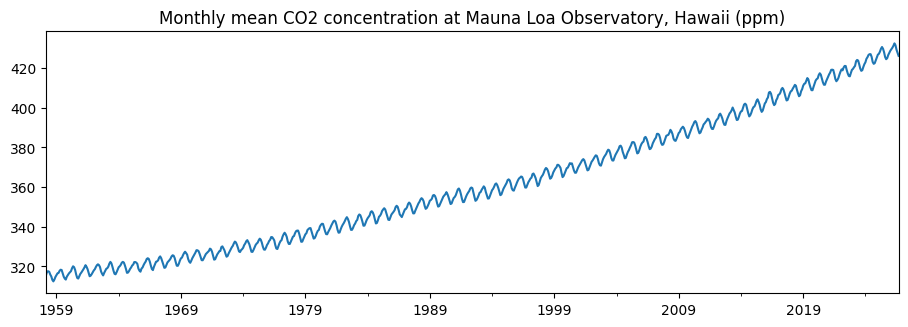

,average
1958-03-01,315.71
1958-04-01,317.45
1958-05-01,317.51
1958-06-01,317.27
1958-07-01,315.87
...,...
2026-05-01,432.34
2026-06-01,431.43
2026-07-01,429.13
2026-08-01,427.55


In [4]:
raw.index = pd.to_datetime(raw[['year', 'month']].assign(day=1))
raw = raw.asfreq("MS")
co2 = raw['average']
co2.plot(title='Monthly mean CO2 concentration at Mauna Loa Observatory, Hawaii (ppm)')
plt.show()
co2

In [5]:
train = co2.loc["1975-01":"2025-12"]
test = co2.loc["2026-01":"2026-09"]
print(len(train),"training months,", len(test), "test months")
raw.loc["1975":"2025"].query("sdev < 0")[["average","ndays","sdev"]]

612 training months, 9 test months


,average,ndays,sdev
1975-12-01,330.77,-1,-9.99
1984-04-01,347.37,2,-9.99


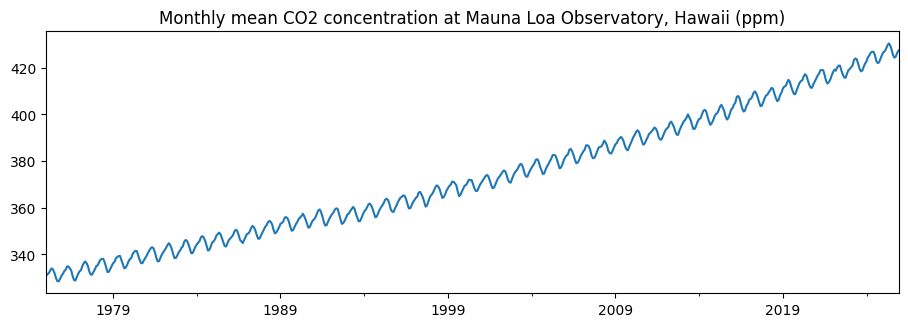

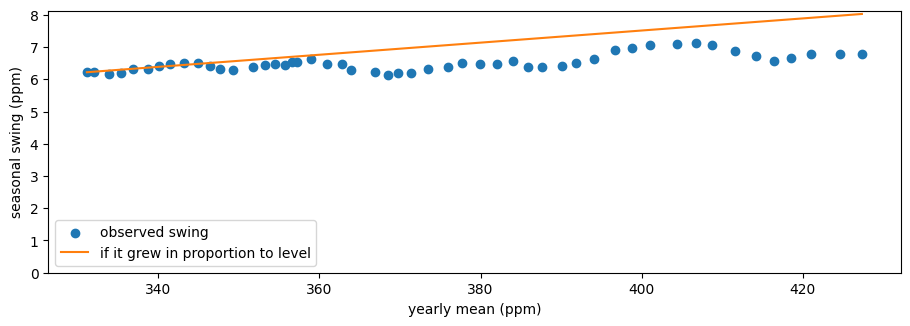

level: 331.127500 -> 427.349167 ppm (+29.058797%)
swing: 6.220000 -> 6.770000 ppm (+8.842444%)


In [6]:
train.plot(title='Monthly mean CO2 concentration at Mauna Loa Observatory, Hawaii (ppm)')
plt.show()
seasonal = (raw["average"] - raw["deseasonalized"]).loc["1975":"2025"]
swing = seasonal.groupby(seasonal.index.year).max() - seasonal.groupby(seasonal.index.year).min()
level = train.groupby(train.index.year).mean()
plt.scatter(level,swing,label="observed swing")

plt.plot(level, swing[1975] * level/level[1975], color="C1", label="if it grew in proportion to level")
plt.ylim(0, None)
plt.xlabel("yearly mean (ppm)")
plt.ylabel("seasonal swing (ppm)")
plt.legend()
plt.show()
print(f"level: {level[1975]:0f} -> {level[2025]:0f} ppm ({level[2025] / level[1975] -1:+0%})")
print(f"swing: {swing[1975]:0f} -> {swing[2025]:0f} ppm ({swing[2025] / swing[1975] -1:+0%})")

ADF, raw series (constant+trend): p = 0.995


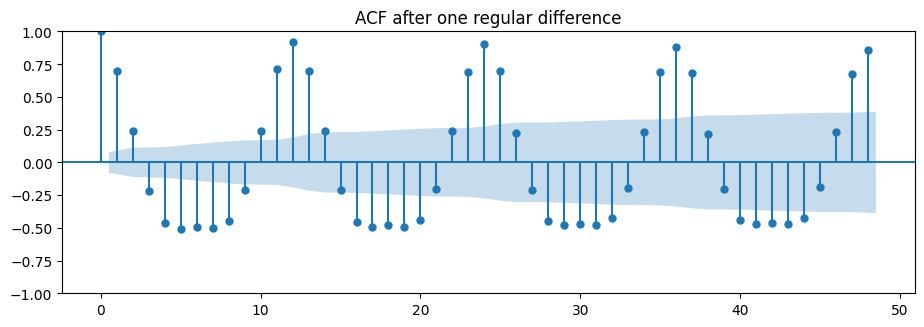

ACF at lags 12, 24, 36, 48: [0.92 0.9  0.88 0.86]


In [9]:
print("ADF, raw series (constant+trend): p =", round(adfuller(train, regression="ct")[1],3))
plot_acf(train.diff().dropna(), lags=48, title="ACF after one regular difference")
plt.show()
print("ACF at lags 12, 24, 36, 48:", acf(train.diff().dropna(), nlags=48)[[12, 24, 36, 48]].round(2))


ADF, z: p = 1.9e-17


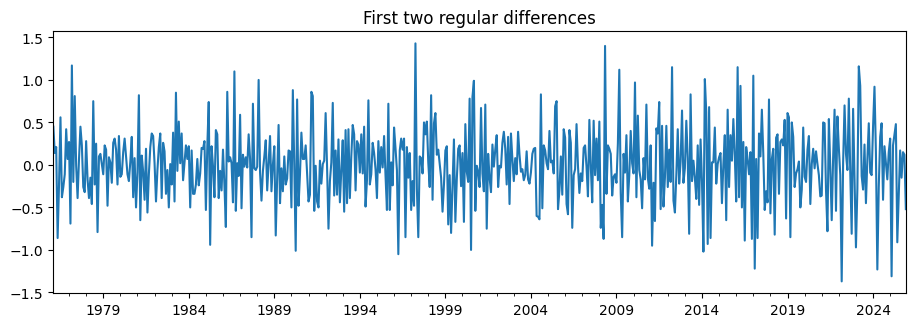

In [12]:
z= train.diff().diff(12).dropna()
print("ADF, z: p =", f"{adfuller(z)[1]:.1e}")
z.plot(title="First two regular differences")
plt.show()

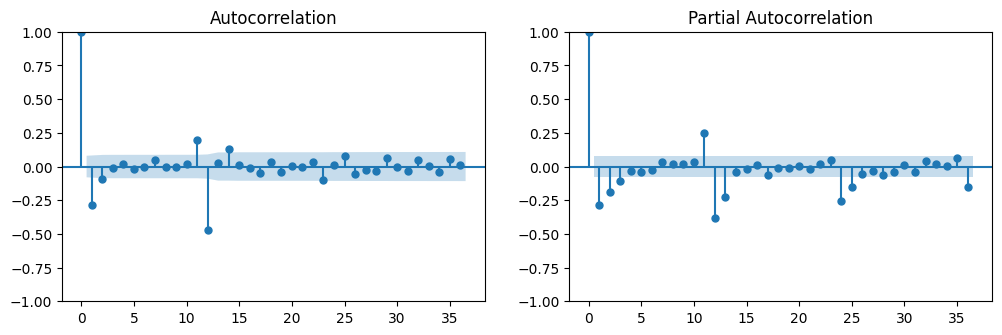

,0
1,-0.28
2,-0.09
3,-0.01
11,0.20
12,-0.47
13,0.03
14,0.13
24,0.01
36,0.01


In [13]:
fig, ax =plt.subplots(1,2,figsize=(12,3.5))
plot_acf(z, lags=36, ax=ax[0])
plot_pacf(z, lags=36, ax=ax[1])
plt.show()

acf_z = acf(z,nlags=36)
lags = [1,2,3,11,12,13,14,24,36]
pd.Series(acf_z[lags], index=lags).round(2)

In [14]:
fit = sm.tsa.SARIMAX(train, order=(1,1,1), seasonal_order=(1,1,1,12)).fit(disp=False)
print(fit.summary().tables[1])

theta, Theta = fit.params["ma.L1"], fit.params["ma.S.L12"]
print("ACF the model predicts at lags 11 and 13:", round(theta*Theta / ((1+theta**2)*(1+Theta**2)),2))
print("ACF in the data at lags 11 and 13", round(acf_z[11],2), round(acf_z[13],2))


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1772      0.089      1.986      0.047       0.002       0.352
ma.L1         -0.5549      0.075     -7.447      0.000      -0.701      -0.409
ar.S.L12       0.0267      0.047      0.564      0.573      -0.066       0.120
ma.S.L12      -0.8903      0.025    -35.073      0.000      -0.940      -0.841
sigma2         0.0984      0.005     19.640      0.000       0.089       0.108
ACF the model predicts at lags 11 and 13: 0.21
ACF in the data at lags 11 and 13 0.2 0.03


In [20]:
candidates = {
    "airline (0,1,1)(0,1,1)":((0, 1, 1), (0, 1, 1, 12)),
    "+ A(1)": ((1, 1, 1), (0, 1, 1, 12)),
    "+ MA(2), q=w": ((0, 1, 2), (0, 1, 1, 12)),
    "+ seasonal AR(1)": ((0, 1, 1), (1, 1, 1, 12)),
    "AR version (1,1,0)(0,1,1)": ((1, 1, 0), (0, 1, 1, 12)),
}
rows = []
for name, (order, seasonal_order) in candidates.items():
    f = sm.tsa.SARIMAX(train, order=order, seasonal_order=seasonal_order).fit(disp=False)
    k = len(f.params)-1
    lb_p=acorr_ljungbox(f.resid.iloc[13:], lags=[24], model_df=k)["lb_pvalue"].iloc[0]
    rows.append({"model": name, "AIC": round(f.aic, 2), "BIC": round(f.bic, 2), "Ljung-Box p": round(lb_p,3)})
pd.DataFrame(rows).sort_values("BIC")

,model,AIC,BIC,Ljung-Box p
0,"airline (0,1,1)(0,1,1)",339.59,352.78,0.764
2,"+ MA(2), q=w",338.11,355.69,0.870
1,+ A(1),338.12,355.70,0.869
3,+ seasonal AR(1),341.35,358.93,0.697
4,"AR version (1,1,0)(0,1,1)",360.46,373.64,0.035
